# Лабораторная работа № 2. Классификация CIFAR-10 с помощью CNN

**Цель:** построить и обучить свёрточную нейронную сеть для классификации изображений CIFAR-10.

**Данные:** 60 000 цветных изображений размером 32 × 32, 10 классов. Из них 45 000 используются для обучения, 5 000 — для валидации и 10 000 — для итогового тестирования. Сеть обучается **с нуля**, без предобученных весов.

## 1. Подготовка

Для воспроизводимости фиксируется случайное зерно. При работе в Colab рекомендуется GPU. Контрольные точки сохраняются после каждой эпохи; параметр `RESUME_TRAINING = True` позволяет продолжить прерванное обучение.

In [2]:
from pathlib import Path
import random
import time
import os

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from tqdm.auto import tqdm

SEED = 42
NUM_EPOCHS = 100
BATCH_SIZE = 128
LEARNING_RATE = 0.1
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
DROPOUT = 0.4
VALIDATION_SIZE = 5000
NUM_WORKERS = 0  # Надёжнее в Jupyter/Colab, без дополнительных процессов DataLoader.

SAVE_TO_GOOGLE_DRIVE = True   # В Colab сохраняем результаты на Google Drive.
RESUME_TRAINING = False      # Изменить на True после прерывания обучения.

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data_dir = Path("data")
output_dir = Path("results")

if SAVE_TO_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        output_dir = Path("/content/drive/MyDrive/CIFAR10_CNN_lab2")
    except ImportError:
        pass  # Локальный Jupyter: сохраняем файлы в папке results.

output_dir.mkdir(parents=True, exist_ok=True)
best_model_path = output_dir / "best_cnn.pt"
last_state_path = output_dir / "last_training_state.pt"

print("Устройство:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Результаты:", output_dir.resolve())

Mounted at /content/drive
Устройство: cuda
GPU: Tesla T4
Результаты: /content/drive/MyDrive/CIFAR10_CNN_lab2


## 2. Загрузка и подготовка данных

На обучающих изображениях применяются случайное горизонтальное отражение и сдвиг через `RandomCrop`: это помогает сети распознавать объект независимо от небольших изменений положения. Для валидации и теста случайные преобразования не используются. Нормализация выполняется отдельно для каждого цветового канала.

In [3]:
cifar_mean = (0.4914, 0.4822, 0.4465)
cifar_std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(cifar_mean, cifar_std),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(cifar_mean, cifar_std),
])

# Используем зеркало исходного архива: официальный сервер CIFAR-10 бывает медленным.
datasets.CIFAR10.url = (
    "https://huggingface.co/datasets/MIT-OL-AI-D/"
    "cifar-10-python/resolve/main/cifar-10-python.tar.gz"
)

train_with_augmentation = datasets.CIFAR10(
    root=str(data_dir), train=True, download=True, transform=train_transform
)
train_without_augmentation = datasets.CIFAR10(
    root=str(data_dir), train=True, download=False, transform=eval_transform
)
test_dataset = datasets.CIFAR10(
    root=str(data_dir), train=False, download=True, transform=eval_transform
)

indices = np.random.default_rng(SEED).permutation(len(train_with_augmentation))
validation_indices = indices[:VALIDATION_SIZE].tolist()
training_indices = indices[VALIDATION_SIZE:].tolist()

train_dataset = Subset(train_with_augmentation, training_indices)
validation_dataset = Subset(train_without_augmentation, validation_indices)

loader_options = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
)
train_loader = DataLoader(train_dataset, shuffle=True, **loader_options)
validation_loader = DataLoader(validation_dataset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)

class_names = test_dataset.classes
print(f"Train: {len(train_dataset)} | Validation: {len(validation_dataset)} | Test: {len(test_dataset)}")

100%|██████████| 170M/170M [00:02<00:00, 61.2MB/s]


Train: 45000 | Validation: 5000 | Test: 10000


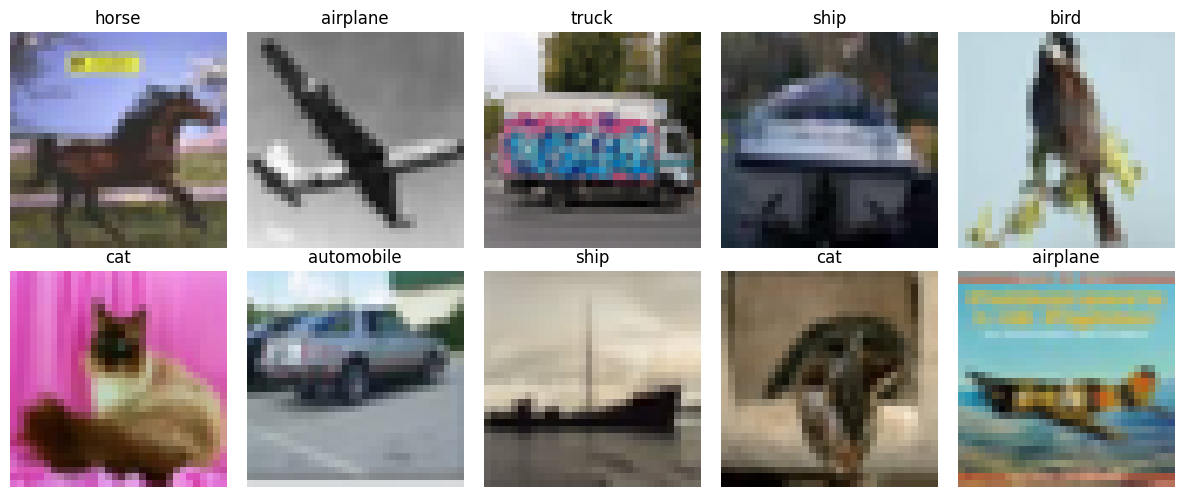

In [4]:
# Примеры изображений CIFAR-10 (обратная нормализация нужна только для показа).
mean_tensor = torch.tensor(cifar_mean).view(3, 1, 1)
std_tensor = torch.tensor(cifar_std).view(3, 1, 1)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, sample_index in zip(axes.flat, training_indices[:10]):
    image, label = train_without_augmentation[sample_index]
    image = (image * std_tensor + mean_tensor).clamp(0, 1)
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_names[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Архитектура нейросети

Используется компактная VGG-подобная CNN. В каждом блоке свёртки `3×3` извлекают признаки, `BatchNorm` стабилизирует обучение, `ReLU` добавляет нелинейность, а `MaxPooling` уменьшает пространственный размер вдвое. После трёх блоков карты признаков преобразуются в вектор и классифицируются полносвязными слоями.

![Схема сети](attachment:cnn_scheme.png)

Размеры после блоков: **(32, 16, 16) → (64, 8, 8) → (128, 4, 4)**. Выход — 10 логитов, по одному на каждый класс.

In [5]:
class SmallVGG(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # Блок 1: 3 × 32 × 32 → 32 × 16 × 16
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Блок 2: 32 × 16 × 16 → 64 × 8 × 8
            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Блок 3: 64 × 8 × 8 → 128 × 4 × 4
            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(DROPOUT),
            nn.Linear(256, 10),
        )

    def forward(self, images):
        return self.classifier(self.features(images))


model = SmallVGG().to(device)
parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
with torch.inference_mode():
    model.eval()
    example_output = model(torch.zeros(2, 3, 32, 32, device=device))
model.train()
print(f"Обучаемых параметров: {parameter_count:,}")
print("Форма выхода для двух изображений:", tuple(example_output.shape))
assert example_output.shape == (2, 10)

Обучаемых параметров: 962,282
Форма выхода для двух изображений: (2, 10)


## 4. Обучение

Используем `CrossEntropyLoss` и SGD с `momentum=0.9`, `weight_decay=5·10⁻⁴`. Скорость обучения плавно уменьшается по косинусному расписанию. `Dropout(0.4)` используется для регуляризации классификатора. После каждой эпохи проверяем качество на валидации и сохраняем лучшую модель; тестовая выборка в обучении не участвует.

In [6]:
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    model.parameters(), lr=LEARNING_RATE,
    momentum=MOMENTUM, weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=NUM_EPOCHS, eta_min=1e-4
)


def train_one_epoch():
    model.train()
    total_loss = 0.0
    correct_predictions = 0
    total_images = 0

    for images, labels in tqdm(train_loader, desc="Обучение", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        predictions = model(images)
        loss = loss_function(predictions, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct_predictions += (predictions.argmax(1) == labels).sum().item()
        total_images += batch_size

    return total_loss / total_images, 100 * correct_predictions / total_images


@torch.inference_mode()
def evaluate(data_loader):
    model.eval()
    total_loss = 0.0
    correct_predictions = 0
    total_images = 0

    for images, labels in data_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        predictions = model(images)
        loss = loss_function(predictions, labels)

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct_predictions += (predictions.argmax(1) == labels).sum().item()
        total_images += batch_size

    return total_loss / total_images, 100 * correct_predictions / total_images

In [7]:
history = {key: [] for key in ("train_loss", "train_acc", "val_loss", "val_acc")}
best_val_accuracy = -1.0
best_epoch = 0
starting_epoch = 1

if RESUME_TRAINING and last_state_path.exists():
    checkpoint = torch.load(last_state_path, map_location=device, weights_only=True)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    history = checkpoint["history"]
    best_val_accuracy = checkpoint["best_val_accuracy"]
    best_epoch = checkpoint["best_epoch"]
    starting_epoch = checkpoint["epoch"] + 1
    print(f"Продолжаем обучение с эпохи {starting_epoch}")

for epoch in range(starting_epoch, NUM_EPOCHS + 1):
    start_time = time.perf_counter()
    train_loss, train_accuracy = train_one_epoch()
    val_loss, val_accuracy = evaluate(validation_loader)
    scheduler.step()

    for key, value in zip(history, (train_loss, train_accuracy, val_loss, val_accuracy)):
        history[key].append(value)

    improved = val_accuracy > best_val_accuracy
    if improved:
        best_val_accuracy = val_accuracy
        best_epoch = epoch
        torch.save({"model": model.state_dict(), "epoch": epoch}, best_model_path)

    torch.save({
        "epoch": epoch, "model": model.state_dict(),
        "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
        "history": history, "best_val_accuracy": best_val_accuracy,
        "best_epoch": best_epoch,
    }, last_state_path)

    duration = time.perf_counter() - start_time
    print(f"Эпоха {epoch:3d}/{NUM_EPOCHS} | "
          f"train: {train_accuracy:5.2f}% | val: {val_accuracy:5.2f}% | "
          f"val loss: {val_loss:.4f} | {duration:.1f} с"
          f"{' ★' if improved else ''}", flush=True)

print(f"Лучшая эпоха: {best_epoch}; validation accuracy: {best_val_accuracy:.2f}%")

Обучение:   0%|          | 0/352 [00:00<?, ?it/s]

Эпоха   1/100 | train: 25.94% | val: 38.32% | val loss: 1.6287 | 32.6 с ★


Обучение:   0%|          | 0/352 [00:00<?, ?it/s]

Эпоха   2/100 | train: 44.94% | val: 50.66% | val loss: 1.4746 | 36.9 с ★


Обучение:   0%|          | 0/352 [00:00<?, ?it/s]

Эпоха   3/100 | train: 56.05% | val: 59.10% | val loss: 1.1269 | 32.5 с ★


... (190 outputs left out)

Обучение:   0%|          | 0/352 [00:00<?, ?it/s]

Эпоха  99/100 | train: 99.18% | val: 91.56% | val loss: 0.3728 | 31.6 с ★


Обучение:   0%|          | 0/352 [00:00<?, ?it/s]

Эпоха 100/100 | train: 99.19% | val: 91.44% | val loss: 0.3765 | 31.7 с
Лучшая эпоха: 99; validation accuracy: 91.56%


## 5. Результаты

Графики позволяют оценить динамику функции потерь и точности на обучающей и валидационной выборках. Для итогового тестирования загружаются веса с лучшей валидационной точностью.

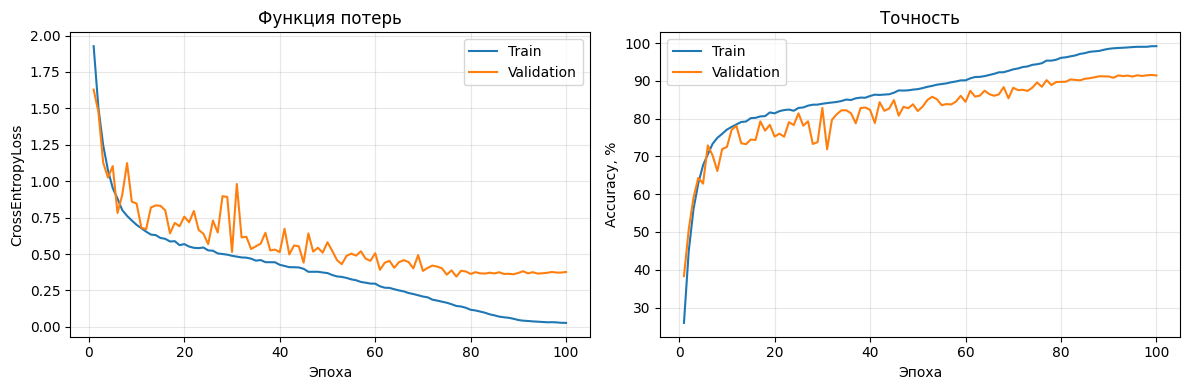

In [8]:
epochs_axis = np.arange(1, len(history["train_acc"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_axis, history["train_loss"], label="Train")
axes[0].plot(epochs_axis, history["val_loss"], label="Validation")
axes[0].set(title="Функция потерь", xlabel="Эпоха", ylabel="CrossEntropyLoss")

axes[1].plot(epochs_axis, history["train_acc"], label="Train")
axes[1].plot(epochs_axis, history["val_acc"], label="Validation")
axes[1].set(title="Точность", xlabel="Эпоха", ylabel="Accuracy, %")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# Тестирование выполняется только после выбора лучшей эпохи по валидации.
best_checkpoint = torch.load(best_model_path, map_location=device, weights_only=True)
model.load_state_dict(best_checkpoint["model"])
test_loss, test_accuracy = evaluate(test_loader)

print(f"Лучшая эпоха: {best_checkpoint['epoch']}")
print(f"Validation accuracy: {best_val_accuracy:.2f}%")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2f}%")
print(f"Test error: {100 - test_accuracy:.2f}%")
print(f"Весá сохранены в: {best_model_path}")

Лучшая эпоха: 99
Validation accuracy: 91.56%
Test loss: 0.3552
Test accuracy: 91.66%
Test error: 8.34%
Весá сохранены в: /content/drive/MyDrive/CIFAR10_CNN_lab2/best_cnn.pt


**Вывод.** Построена и обучена VGG-подобная CNN с семью свёрточными слоями. Пространственный размер карт признаков последовательно уменьшается за счёт MaxPooling, а их число увеличивается с 32 до 128. Случайные преобразования изображений, Dropout и weight decay используются для улучшения обобщающей способности. Итоговая точность измеряется на отдельной тестовой выборке, не участвовавшей в подборе весов и выборе эпохи.